# 04 · Entrenamiento del modelo (tarea 2.2, CRISP-DM fase 4)

Técnica elegida en la tarea 2.1: **FaceNet InceptionResnetV1 (VGGFace2)** con embeddings y similitud coseno contra la plantilla del usuario.

**¿Qué significa "entrenar" aquí?** La red se usa **preentrenada y congelada**, sin ajuste fino. Por eso el entrenamiento consiste en el **registro
(enrolamiento)** de las 24 identidades: calcular la plantilla de cada una con sus fotos de *train*. No hay curvas de pérdida para este modelo.

**¿Por qué no hacer ajuste fino de FaceNet?**
1. En validación ya separa perfectamente (EER 0,00 %), así que la validación no podría mostrar ninguna mejora: cualquier ajuste sería a ciegas.
2. Ajustarla con solo 1 362 fotos de 24 personas la especializaría en esas personas y empeoraría la generalización a usuarios nuevos, como se vio con
   (a1) y (a2), que sobreajustan.
3. Con la red congelada, registrar un usuario nuevo no exige reentrenar nada.

Además se entrena el **modelo de control (a2) ResNet-18 ImageNet**, que se evaluará también en prueba como control del sesgo de famosos.
Usa los mismos hiperparámetros fijos de la tarea 2.1, y en este caso sí hay curvas de entrenamiento y validación.

Ambos se guardan como **paquete reutilizable** (`models/<nombre>/`, ignorado por git):
- red exportada con **TorchScript**, que se carga sin facenet-pytorch;
- plantillas;
- `config.json`, con el umbral todavía vacío (se fija en la tarea 2.3 usando validación).

El conjunto de prueba no se carga.

In [1]:
import sys, time, json, hashlib, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, cv2, sklearn, facenet_pytorch
from src import config as C, data as D, models as M, metrics as MT, verification as V, pipeline as P
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
np.random.seed(C.SEED); torch.manual_seed(C.SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
VERS = {"python": platform.python_version(), "torch": torch.__version__, "opencv": cv2.__version__, "numpy": np.__version__,
        "scikit-learn": sklearn.__version__, "facenet-pytorch": "2.6.0",
        "gpu": torch.cuda.get_device_name(0) if DEV == "cuda" else None}
print(VERS)
sp = D.load_split_table()
cache = np.load(C.DATA_PROCESSED / "faces160.npz", allow_pickle=True)
pos = {f: k for k, f in enumerate(cache["filename"])}
REG = sorted(sp.loc[sp.role == "registrada", "person"].unique())
tr = sp[sp.split == "train"].reset_index(drop=True); va = sp[sp.split == "val"].reset_index(drop=True)
X_tr = cache["X"][[pos[f] for f in tr.filename]]; X_va = cache["X"][[pos[f] for f in va.filename]]
assert (tr.role == "registrada").all() and (va.split == "val").all()
print(f"train {len(tr)} | val {len(va)} | test: no se carga")
TIEMPOS = {}
def sha256(p): return hashlib.sha256(open(p, "rb").read()).hexdigest()

{'python': '3.10.4', 'torch': '2.11.0+cu128', 'opencv': '5.0.0', 'numpy': '2.2.6', 'scikit-learn': '1.7.2', 'facenet-pytorch': '2.6.0', 'gpu': 'NVIDIA GeForce RTX 5060'}


train 1362 | val 574 | test: no se carga


## 1. FaceNet VGGFace2: carga y exportación a TorchScript

In [2]:
t0 = time.perf_counter(); fn = M.facenet("vggface2", DEV); TIEMPOS["carga_facenet_pytorch_s"] = time.perf_counter() - t0
w = Path(C.os.environ["TORCH_HOME"]) / "checkpoints" / "20180402-114759-vggface2.pt"
PK = C.MODELS_DIR / "verificador_facenet_vggface2"; PK.mkdir(parents=True, exist_ok=True)
err = P.export_torchscript(fn, PK / "red.ts", "facenet", device=DEV)
print(f"Pesos: {w.name} ({w.stat().st_size/1e6:.1f} MB) sha256 {sha256(w)[:16]}… | parámetros {sum(p.numel() for p in fn.parameters())/1e6:.2f} M")
print(f"TorchScript guardado ({(PK/'red.ts').stat().st_size/1e6:.1f} MB); diferencia máxima con la red original: {err:.2e}")

Pesos: 20180402-114759-vggface2.pt (111.9 MB) sha256 281cebca8662831a… | parámetros 27.91 M
TorchScript guardado (112.9 MB); diferencia máxima con la red original: 3.08e-05


## 2. Registro (enrolamiento) de las 24 identidades con sus fotos de train

In [3]:
if DEV == "cuda": torch.cuda.synchronize()
t0 = time.perf_counter()
E_tr = M.embed(fn, X_tr, "facenet", DEV)
T = V.templates(E_tr, tr.person.values, REG)
if DEV == "cuda": torch.cuda.synchronize()
TIEMPOS["registro_24_usuarios_GPU_s"] = time.perf_counter() - t0
n_foto = tr.person.value_counts().reindex(REG)
# Registro de UN usuario (con lectura de disco), por usuario, en CPU y GPU
reg_t = []
for dev in ([DEV] if DEV == "cuda" else []) + ["cpu"]:
    m = fn if dev == DEV else M.facenet("vggface2", "cpu")
    for p in REG:
        paths = tr.loc[tr.person == p, "filename"].map(lambda f: str(C.FACES_DIR / f)).tolist()
        t0 = time.perf_counter()
        e = M.embed(m, D.load_images(paths), "facenet", dev); tpl = e.mean(0); tpl /= np.linalg.norm(tpl)
        reg_t.append({"dispositivo": "GPU" if dev == "cuda" else "CPU", "usuario": p, "n_fotos": len(paths), "segundos": time.perf_counter() - t0})
reg_t = pd.DataFrame(reg_t)
print(f"Registro de las 24 identidades (embeddings ya en memoria, GPU): {TIEMPOS['registro_24_usuarios_GPU_s']:.2f} s")
reg_t.groupby("dispositivo").agg(fotos_media=("n_fotos", "mean"), s_mediana=("segundos", "median"), s_max=("segundos", "max")).round(3)

Registro de las 24 identidades (embeddings ya en memoria, GPU): 1.39 s


,fotos_media,s_mediana,s_max
dispositivo,,,
CPU,56.75,2.223,3.228
GPU,56.75,0.178,0.532


In [4]:
cfg = {"tecnica": "FaceNet InceptionResnetV1 preentrenada (congelada) + plantilla media + coseno",
       "pesos": w.name, "pesos_sha256": sha256(w),
       "fuente_pesos": "https://github.com/timesler/facenet-pytorch/releases (conversion de davidsandberg/facenet, VGGFace2)",
       "entrada": "rostro recortado 160x160 RGB (como Dataset/Faces)", "normalizacion": "facenet",
       "normalizacion_formula": "(x - 127.5) / 128", "metrica": "coseno (embeddings y plantillas L2-normalizados)",
       "plantilla": "media de los embeddings de las fotos de train del usuario, renormalizada",
       "umbral": None, "umbral_nota": "se fija en la tarea 2.3 con el conjunto de validacion",
       "semilla": C.SEED, "fotos_registro_por_usuario": n_foto.to_dict(), "versiones": VERS,
       "creado": time.strftime("%Y-%m-%d %H:%M")}
P.save_package(PK, PK / "red.ts", T, REG, cfg)
print(sorted(p.name for p in PK.iterdir()))

['config.json', 'plantillas.npz', 'red.ts']


Similitud entre plantillas: cuanto más baja fuera de la diagonal, más separados están los usuarios registrados.

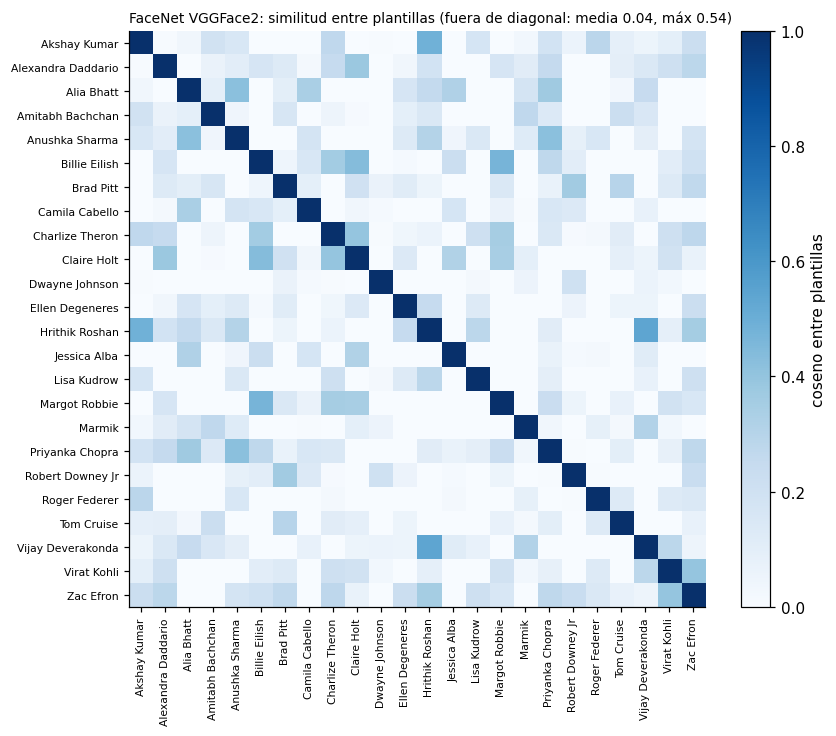

Par de plantillas más parecido: Hrithik Roshan – Vijay Deverakonda (0.536)


In [5]:
TT = T @ T.T
fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(TT, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(REG))); ax.set_xticklabels(REG, rotation=90, fontsize=7); ax.set_yticks(range(len(REG))); ax.set_yticklabels(REG, fontsize=7)
plt.colorbar(im, fraction=0.046, label="coseno entre plantillas")
off = TT[~np.eye(len(REG), dtype=bool)]; i, j = np.unravel_index(np.argmax(TT - 2*np.eye(len(REG))), TT.shape)
ax.set_title(f"FaceNet VGGFace2: similitud entre plantillas (fuera de diagonal: media {off.mean():.2f}, máx {off.max():.2f})", loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(C.FIGS / "04_similitud_plantillas.png"); plt.show()
print(f"Par de plantillas más parecido: {REG[i]} – {REG[j]} ({TT[i, j]:.3f})")

## 3. Comprobación: recargar el paquete (sin facenet-pytorch) y reproducir la validación de la tarea 2.1

In [6]:
del fn; torch.cuda.empty_cache()
prev = np.load(C.DATA_PROCESSED / "tarea21_puntuaciones_val.npz")["b1_facenet_vggface2"]
for dev in ([DEV] if DEV == "cuda" else []) + ["cpu"]:
    vf = P.Verifier(PK, device=dev)
    S = np.concatenate([(vf.embed(X_va[k:k+128]) @ vf.T.T).cpu().numpy() for k in range(0, len(X_va), 128)])
    sc = V.split_scores(S, va.person.values, va.role.values, vf.users)
    r = MT.summary(sc["genuinas"], sc["impostoras"])
    TIEMPOS[f"carga_paquete_{'GPU' if dev=='cuda' else 'CPU'}_s"] = vf.load_seconds
    print(f"[{dev}] carga {vf.load_seconds:.2f} s | EER val {r['EER']*100:.2f} % | AUC {r['AUC']:.4f} | diferencia máx. con 2.1: {np.abs(S - prev).max():.2e}")

[cuda] carga 2.61 s | EER val 0.00 % | AUC 1.0000 | diferencia máx. con 2.1: 1.51e-04


[cpu] carga 0.65 s | EER val 0.00 % | AUC 1.0000 | diferencia máx. con 2.1: 5.34e-04


## 4. Tiempos de inferencia

In [7]:
def cron(f, n=60, warm=5):
    t = []
    for k in range(n + warm):
        t0 = time.perf_counter(); f(k); dt = time.perf_counter() - t0
        if k >= warm: t.append(dt)
    return float(np.median(t) * 1000), float(np.percentile(t, 95) * 1000)
paths = va.filename.map(lambda f: str(C.FACES_DIR / f)).values
filas = []
for dev in ([DEV] if DEV == "cuda" else []) + ["cpu"]:
    vf = P.Verifier(PK, device=dev); d = "GPU" if dev == "cuda" else "CPU"
    med, p95 = cron(lambda k: vf.score(D.read_rgb(paths[k % len(paths)]), REG[k % 24]))
    filas.append({"medida": "verificación 1 a 1 (leer JPG + embedding + coseno)", "dispositivo": d, "mediana_ms": med, "p95_ms": p95})
    xb = X_va[:64]
    med, p95 = cron(lambda k: vf.embed(xb).cpu(), n=10, warm=2)
    filas.append({"medida": "embeddings por lote de 64 (ms por imagen)", "dispositivo": d, "mediana_ms": med / 64, "p95_ms": p95 / 64})
    filas.append({"medida": "carga del paquete", "dispositivo": d, "mediana_ms": vf.load_seconds * 1000, "p95_ms": np.nan})
    g = reg_t[reg_t.dispositivo == d]
    filas.append({"medida": f"registro de un usuario ({g.n_fotos.median():.0f} fotos, con lectura de disco)", "dispositivo": d,
                  "mediana_ms": g.segundos.median() * 1000, "p95_ms": g.segundos.quantile(0.95) * 1000})
tiempos = pd.DataFrame(filas); tiempos.to_csv(C.DOCS / "04_tiempos_facenet.csv", index=False); tiempos.round(2)

,medida,dispositivo,mediana_ms,p95_ms
0,verificación 1 a 1 (leer JPG + embedding + cos...,GPU,18.12,27.45
1,embeddings por lote de 64 (ms por imagen),GPU,0.51,0.60
2,carga del paquete,GPU,989.06,NaN
3,"registro de un usuario (54 fotos, con lectura ...",GPU,177.81,219.81
4,verificación 1 a 1 (leer JPG + embedding + cos...,CPU,88.58,246.33
5,embeddings por lote de 64 (ms por imagen),CPU,34.60,44.84
6,carga del paquete,CPU,1419.12,NaN
7,"registro de un usuario (54 fotos, con lectura ...",CPU,2222.53,2899.95


## 5. Modelo de control (a2) ResNet-18 ImageNet

Mismos hiperparámetros fijos que en la tarea 2.1: AdamW con OneCycle, lr 3e-4, 40 épocas, lote 64, label smoothing 0,1, weight decay 5e-4
y el mismo aumento de datos. Se guarda la **última época**, sin elegir época con validación. La curva de validación es la exactitud de
clasificación de las fotos de validación de las 24 registradas, y es solo informativa.

In [8]:
X_mon = X_va[(va.role == "registrada").values]; cls = {p: k for k, p in enumerate(REG)}
y_mon = va.loc[va.role == "registrada", "person"].map(cls).values; y_tr = tr.person.map(cls).values
torch.manual_seed(C.SEED)
net, hist, secs = M.train_classifier(M.ResNet18Face(len(REG)), X_tr, y_tr, "imagenet", DEV, epochs=40, lr=3e-4, seed=C.SEED, X_mon=X_mon, y_mon=y_mon)
hist = pd.DataFrame(hist); hist.to_csv(C.DOCS / "04_historial_control_a2.csv", index=False)
TIEMPOS["entrenamiento_control_a2_s"] = secs
PC = C.MODELS_DIR / "control_resnet18_imagenet"; PC.mkdir(parents=True, exist_ok=True)
torch.save({"state_dict": net.state_dict(), "clases": REG}, PC / "pesos_entrenados.pt")
err = P.export_torchscript(net, PC / "red.ts", "imagenet", device=DEV)
E_tr2 = M.embed(net, X_tr, "imagenet", DEV); T2 = V.templates(E_tr2, tr.person.values, REG)
P.save_package(PC, PC / "red.ts", T2, REG, {"tecnica": "ResNet-18 ImageNet ajustada como clasificador de 24 registradas (CONTROL del sesgo de famosos)",
    "entrada": "160x160 RGB", "normalizacion": "imagenet", "metrica": "coseno", "plantilla": "media de train",
    "hiperparametros": {"optimizador": "AdamW+OneCycle", "lr": 3e-4, "epocas": 40, "lote": 64, "label_smoothing": 0.1, "weight_decay": 5e-4},
    "umbral": None, "semilla": C.SEED, "versiones": VERS, "creado": time.strftime("%Y-%m-%d %H:%M")})
vc = P.Verifier(PC, device=DEV)
S2 = np.concatenate([(vc.embed(X_va[k:k+128]) @ vc.T.T).cpu().numpy() for k in range(0, len(X_va), 128)])
sc2 = V.split_scores(S2, va.person.values, va.role.values, REG); r2 = MT.summary(sc2["genuinas"], sc2["impostoras"])
print(f"Entrenamiento {secs:.0f} s | acc train {hist.acc_train.iloc[-1]:.3f} | acc val {hist.acc_val.iloc[-1]:.3f} | TorchScript dif. {err:.2e}")
print(f"Control (a2) recargado desde el paquete: EER val {r2['EER']*100:.2f} % | AUC {r2['AUC']:.4f} (en la tarea 2.1 fue 3,55 %; la GPU no es 100 % determinista)")

Entrenamiento 72 s | acc train 1.000 | acc val 0.970 | TorchScript dif. 0.00e+00
Control (a2) recargado desde el paquete: EER val 3.55 % | AUC 0.9929 (en la tarea 2.1 fue 3,55 %; la GPU no es 100 % determinista)


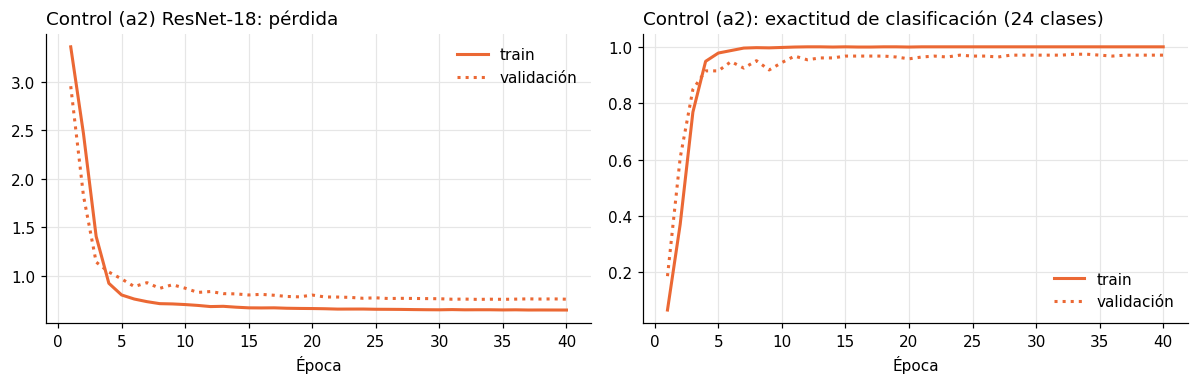

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(hist.epoca, hist.loss_train, color="#eb6834", lw=2, label="train"); axes[0].plot(hist.epoca, hist.loss_val, color="#eb6834", lw=2, ls=":", label="validación")
axes[1].plot(hist.epoca, hist.acc_train, color="#eb6834", lw=2, label="train"); axes[1].plot(hist.epoca, hist.acc_val, color="#eb6834", lw=2, ls=":", label="validación")
axes[0].set_title("Control (a2) ResNet-18: pérdida", loc="left"); axes[1].set_title("Control (a2): exactitud de clasificación (24 clases)", loc="left")
for a in axes: a.set_xlabel("Época"); a.legend(frameon=False)
plt.tight_layout(); plt.savefig(C.FIGS / "04_curvas_control_a2.png"); plt.show()

In [10]:
json.dump({"tiempos": TIEMPOS, "versiones": VERS, "control_a2_val": r2,
           "facenet_tiempos_tabla": tiempos.to_dict("records")}, open(C.DOCS / "04_resumen_entrenamiento.json", "w"), indent=2, default=float)
print(json.dumps(TIEMPOS, indent=1, default=float))

{
 "carga_facenet_pytorch_s": 3.386175199999343,
 "registro_24_usuarios_GPU_s": 1.3864799000002677,
 "carga_paquete_GPU_s": 2.606902600000467,
 "carga_paquete_CPU_s": 0.6511608000000706,
 "entrenamiento_control_a2_s": 71.67341423034668
}
